# Comparing independently evolved luciferases

**Question:** do luciferases that evolved separately share any protein-sequence or physicochemical features?

This notebook re-runs the whole analysis from the curated dataset (62 luminous proteins in 10 families, plus 19 non-luminous controls) and shows the key results. Plain-language explanations are in `docs/PROJECT_REPORT.md`.

In [1]:
import os, sys
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
sys.path.insert(0, os.getcwd())
import pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 160)

## 1. Dataset check (W3: biological databases)
The curated FASTA files and manifest are checked against `data/seeds.csv` (offline).

In [2]:
import subprocess
print(subprocess.run([sys.executable, '-m', 'src.verify_data'], capture_output=True, text=True).stdout)

note: no InterPro/Pfam annotation for 15: XRP75328.1 BCK50966.1 Q9BLZ2 Q6UQE3 I7GGY2 H3JS09 U3TKG7 H3JS11 U3TIM6 H3JS17 H3JS19 H3JS13 BAD08210.1 QOS14273.1 XRP75329.1
firefly         {'luciferase': 8, 'control': 2}
renilla_type    {'luciferase': 3, 'control': 3}
bacterial_luxa  {'luciferase': 10, 'control': 3}
fungal_luz      {'luciferase': 9, 'control': 3}
copepod         {'luciferase': 10}
dinoflagellate  {'luciferase': 8}
ostracod        {'luciferase': 3}
click_beetle    {'luciferase': 4, 'control': 1}
photoprotein    {'luciferase': 6, 'control': 4}
decapod_shrimp  {'luciferase': 1, 'control': 3}
ISSUES none
DATASET VERIFIED



## 2. Protein properties (W14: proteomics)
Biopython ProtParam: length, molecular weight, pI, GRAVY, aromaticity, amino-acid composition.

In [3]:
from src import features
features.run()
pd.read_csv('results/features_by_family.csv')

wrote 81 proteins to results/features.csv


,family,role,n,length_median,length_min,length_max,molecular_weight_kda_median,molecular_weight_kda_min,molecular_weight_kda_max,isoelectric_point_median,isoelectric_point_min,isoelectric_point_max,gravy_median,gravy_min,gravy_max,aromaticity_median,aromaticity_min,aromaticity_max
0,firefly,luciferase,8,547.5,545,550,60.471,60.017,60.744,6.450,5.903,8.395,-0.080,-0.110,-0.040,0.093,0.082,0.101
1,firefly,control,2,535.0,526,544,59.236,58.534,59.938,7.082,5.909,8.255,0.004,-0.004,0.012,0.085,0.079,0.091
2,renilla_type,luciferase,3,311.0,311,322,36.113,36.022,37.549,5.860,5.670,5.978,-0.430,-0.535,-0.422,0.119,0.119,0.127
3,renilla_type,control,3,296.0,293,314,33.246,33.107,36.226,5.029,4.949,5.907,-0.228,-0.531,-0.137,0.109,0.098,0.118
4,bacterial_luxa,luciferase,10,354.5,346,362,40.356,39.364,41.401,5.384,4.949,5.748,-0.378,-0.444,-0.319,0.104,0.099,0.122
5,bacterial_luxa,control,3,381.0,376,382,41.736,41.566,41.802,5.694,5.485,5.799,-0.192,-0.388,-0.175,0.079,0.079,0.090
6,fungal_luz,luciferase,9,261.0,246,267,29.700,27.396,30.381,8.633,6.513,9.376,-0.236,-0.327,-0.180,0.086,0.080,0.093
7,fungal_luz,control,3,267.0,263,283,29.570,28.632,31.416,8.159,6.646,8.760,-0.127,-0.172,0.092,0.080,0.056,0.092
8,copepod,luciferase,10,210.5,185,223,22.981,19.900,24.322,7.076,5.179,9.117,-0.101,-0.343,0.095,0.053,0.047,0.064
9,dinoflagellate,luciferase,8,1237.0,914,1242,136.901,102.187,137.286,6.162,5.763,7.497,-0.491,-0.563,-0.290,0.101,0.084,0.103


## 3. Pairwise alignment (W6–W8: similarity, global and local alignment)
Needleman–Wunsch identity for all 1,653 pairs, plus Smith–Waterman z-scores against shuffled sequences (z near 0 = chance). Takes about 2–3 minutes.

HEAGAWGHEE
--P-AWHEAE

Biopython score for the same settings: -8 (matches the hand-written DP)


                           global_identity_pct_count  global_identity_pct_median  global_identity_pct_min  global_identity_pct_max  local_zscore_count  local_zscore_median  local_zscore_min  local_zscore_max
category                                                                                                                                                                                                       
control vs control                                19                   33.460076                20.134228                78.215223                  19            39.487512          1.704453        160.946855
cross-family                                    1682                   19.882640                 0.182482                53.690037                1682             0.031183         -3.084146        189.546691
cross-family (control)                          1217                   18.791946                 0.540541                48.529412                1217            -0.038

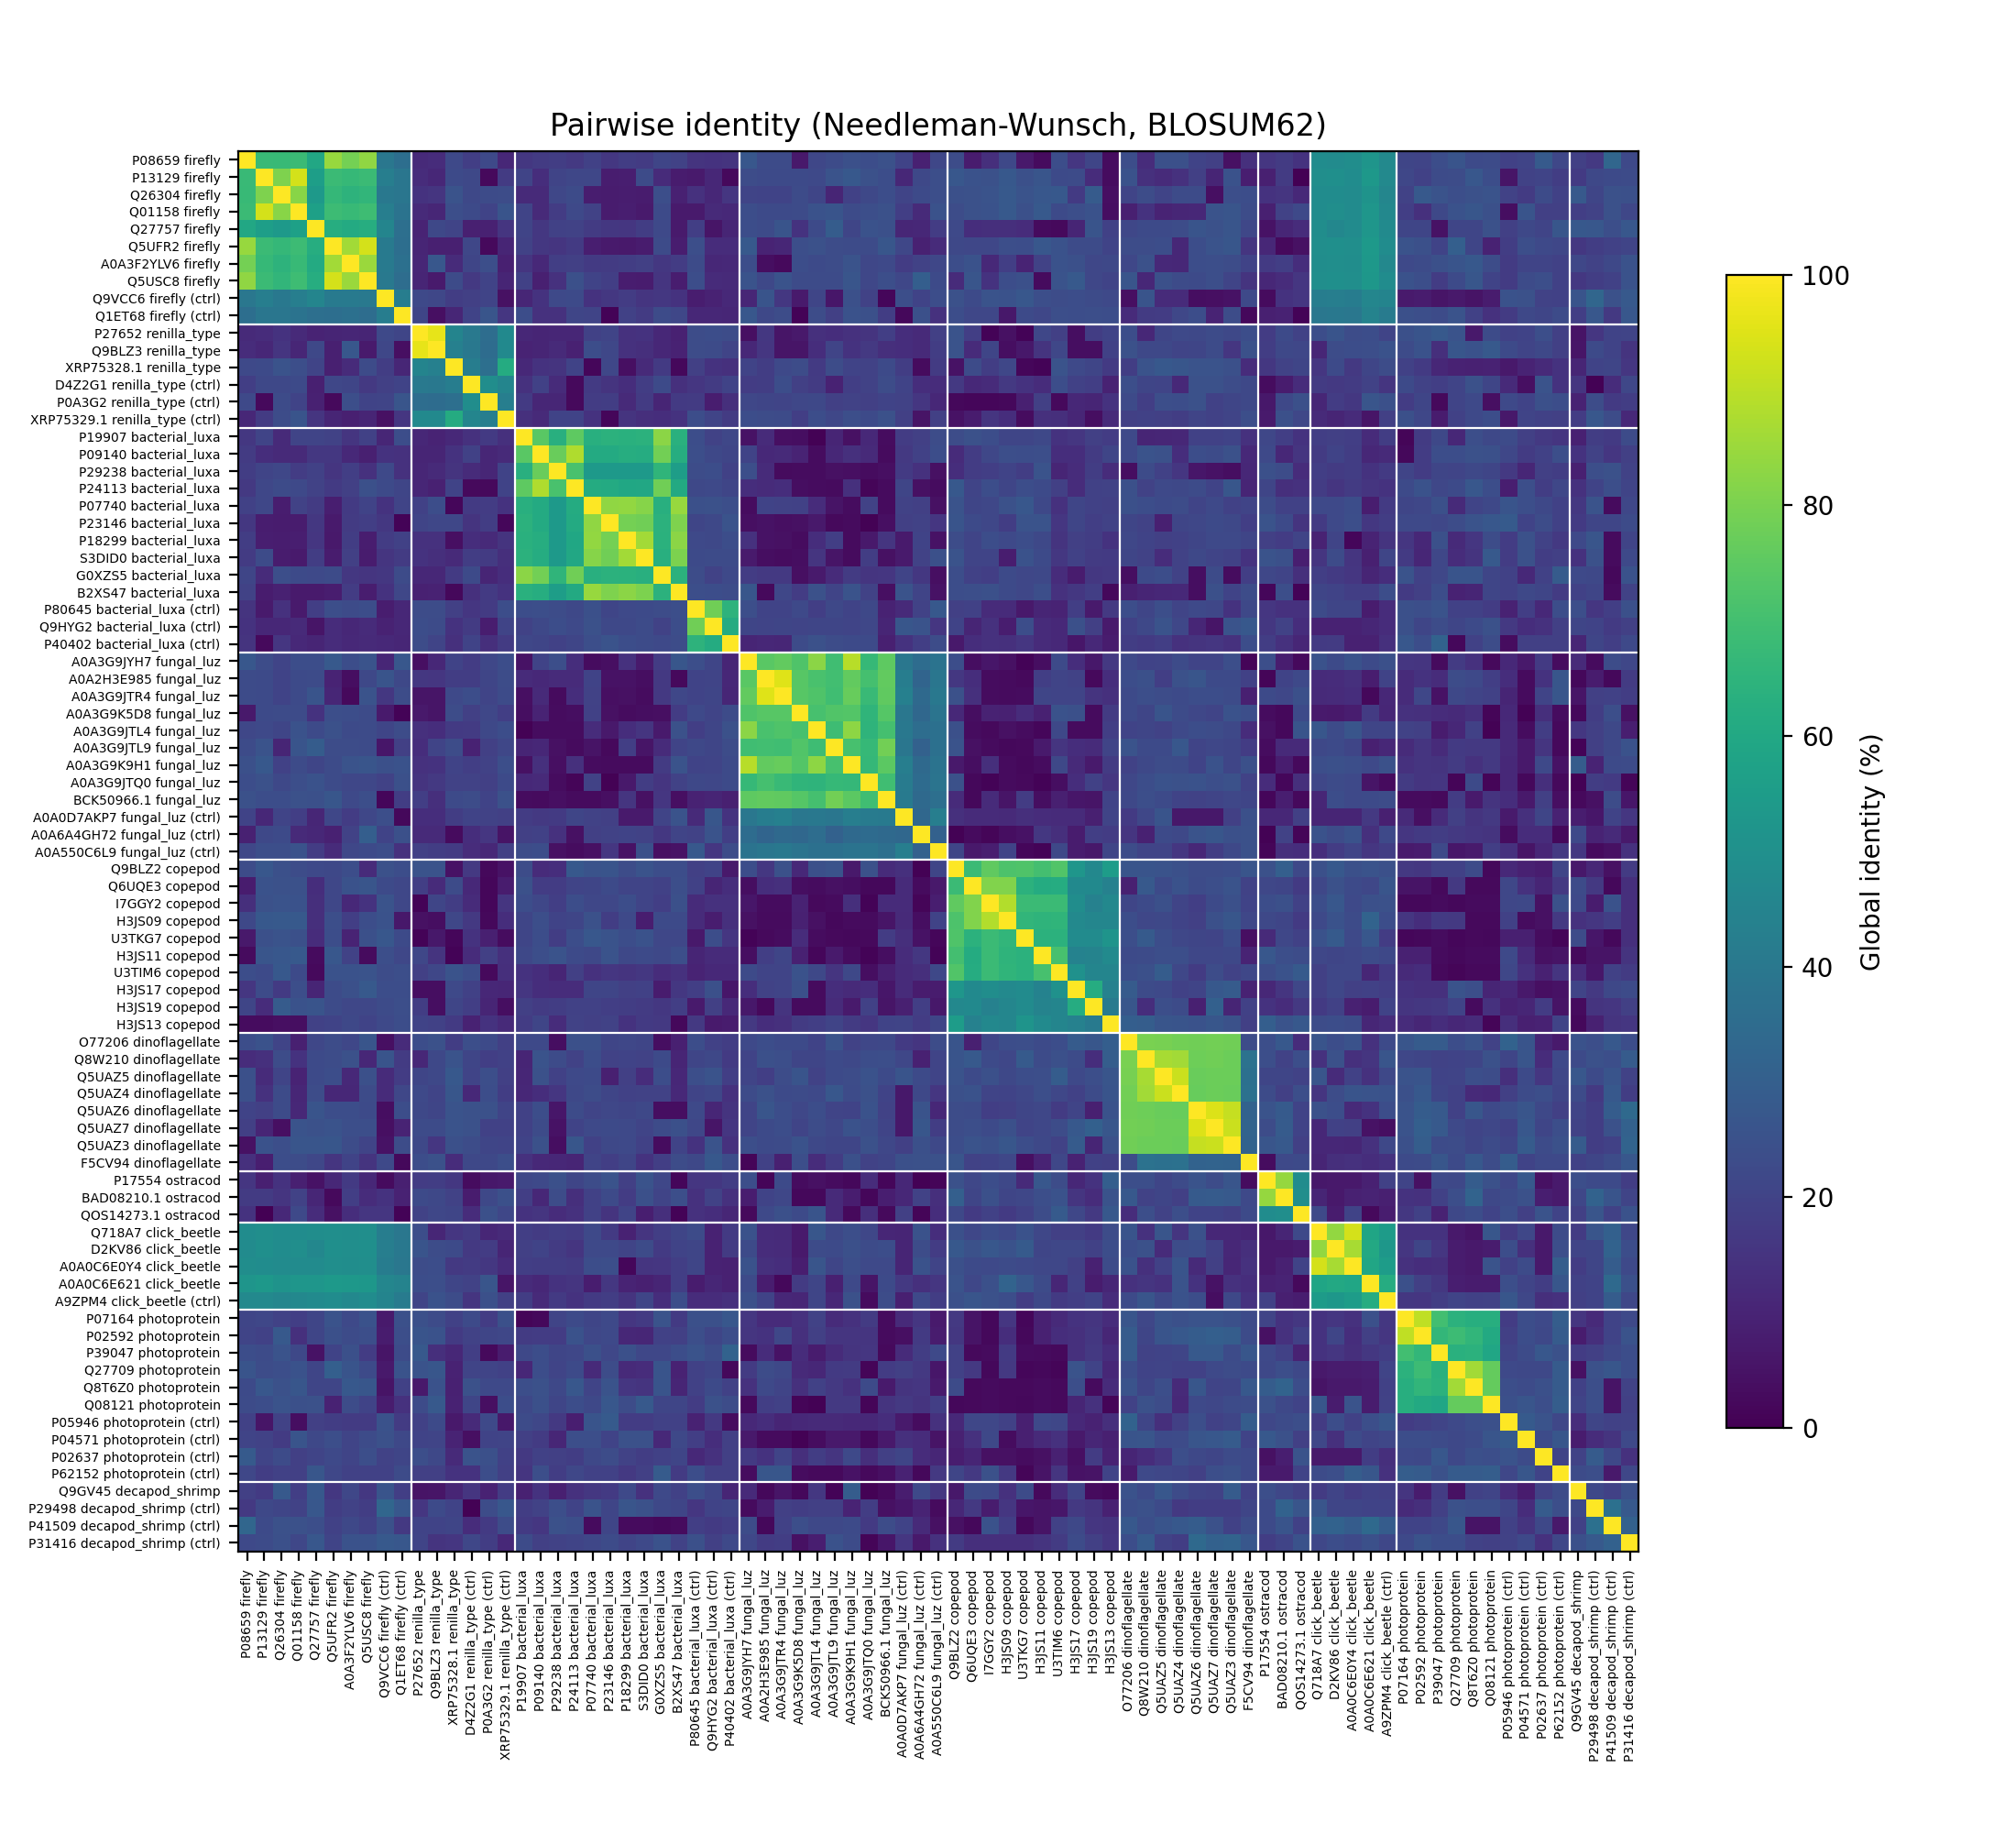

In [4]:
from src import align
align.run()
display(Image('results/figures/identity_heatmap.png', width=750))

In [5]:
print(open('results/example_alignments.txt').read()[:3000])

=== Global (Needleman-Wunsch): P08659 (firefly) vs P13129 (firefly) | score 1949.5 ===
target            0 ---MEDAKNIKKGPAPFYPLEDGTAGEQLHKAMKRYALVPGTIAFTDAHIEVNITYAEYF
                  0 ---||...||..||.||||.|.|.||.||.|.|.|||..-|.||||.|...|...||||.
query             0 MENMENDENIVVGPKPFYPIEEGSAGTQLRKYMERYAKL-GAIAFTNAVTGVDYSYAEYL

target           57 EMSVRLAEAMKRYGLNTNHRIVVCSENSLQFFMPVLGALFIGVAVAPANDIYNERELLNS
                 60 |.|..|..|...|||....||..||||...||.||...|||||.|||.|.||..|||..|
query            59 EKSCCLGKALQNYGLVVDGRIALCSENCEEFFIPVIAGLFIGVGVAPTNEIYTLRELVHS

target          117 MNISQPTVVFVSKKGLQKILNVQKKLPIIQKIIIMDSKTDYQGFQSMYTFVTSHLPPGFN
                120 ..||.||.||.|||||.|...|||....|..|.|.|||.||.|.|...||.....||||.
query           119 LGISKPTIVFSSKKGLDKVITVQKTVTTIKTIVILDSKVDYRGYQCLDTFIKRNTPPGFQ

target          177 EYDFVPESFDRDKTIALIMNSSGSTGLPKGVALPHRTACVRFSHARDPIFGNQIIPDTAI
                180 ...|.....||....||||||||||||||||.|.|.....|||||||||.|||..|.||.
query           179

## 4. Dot plots (W9)

P08659 vs P13129: 479 dots
P08659 vs A9ZPM4: 334 dots


P08659 vs P19907: 6 dots


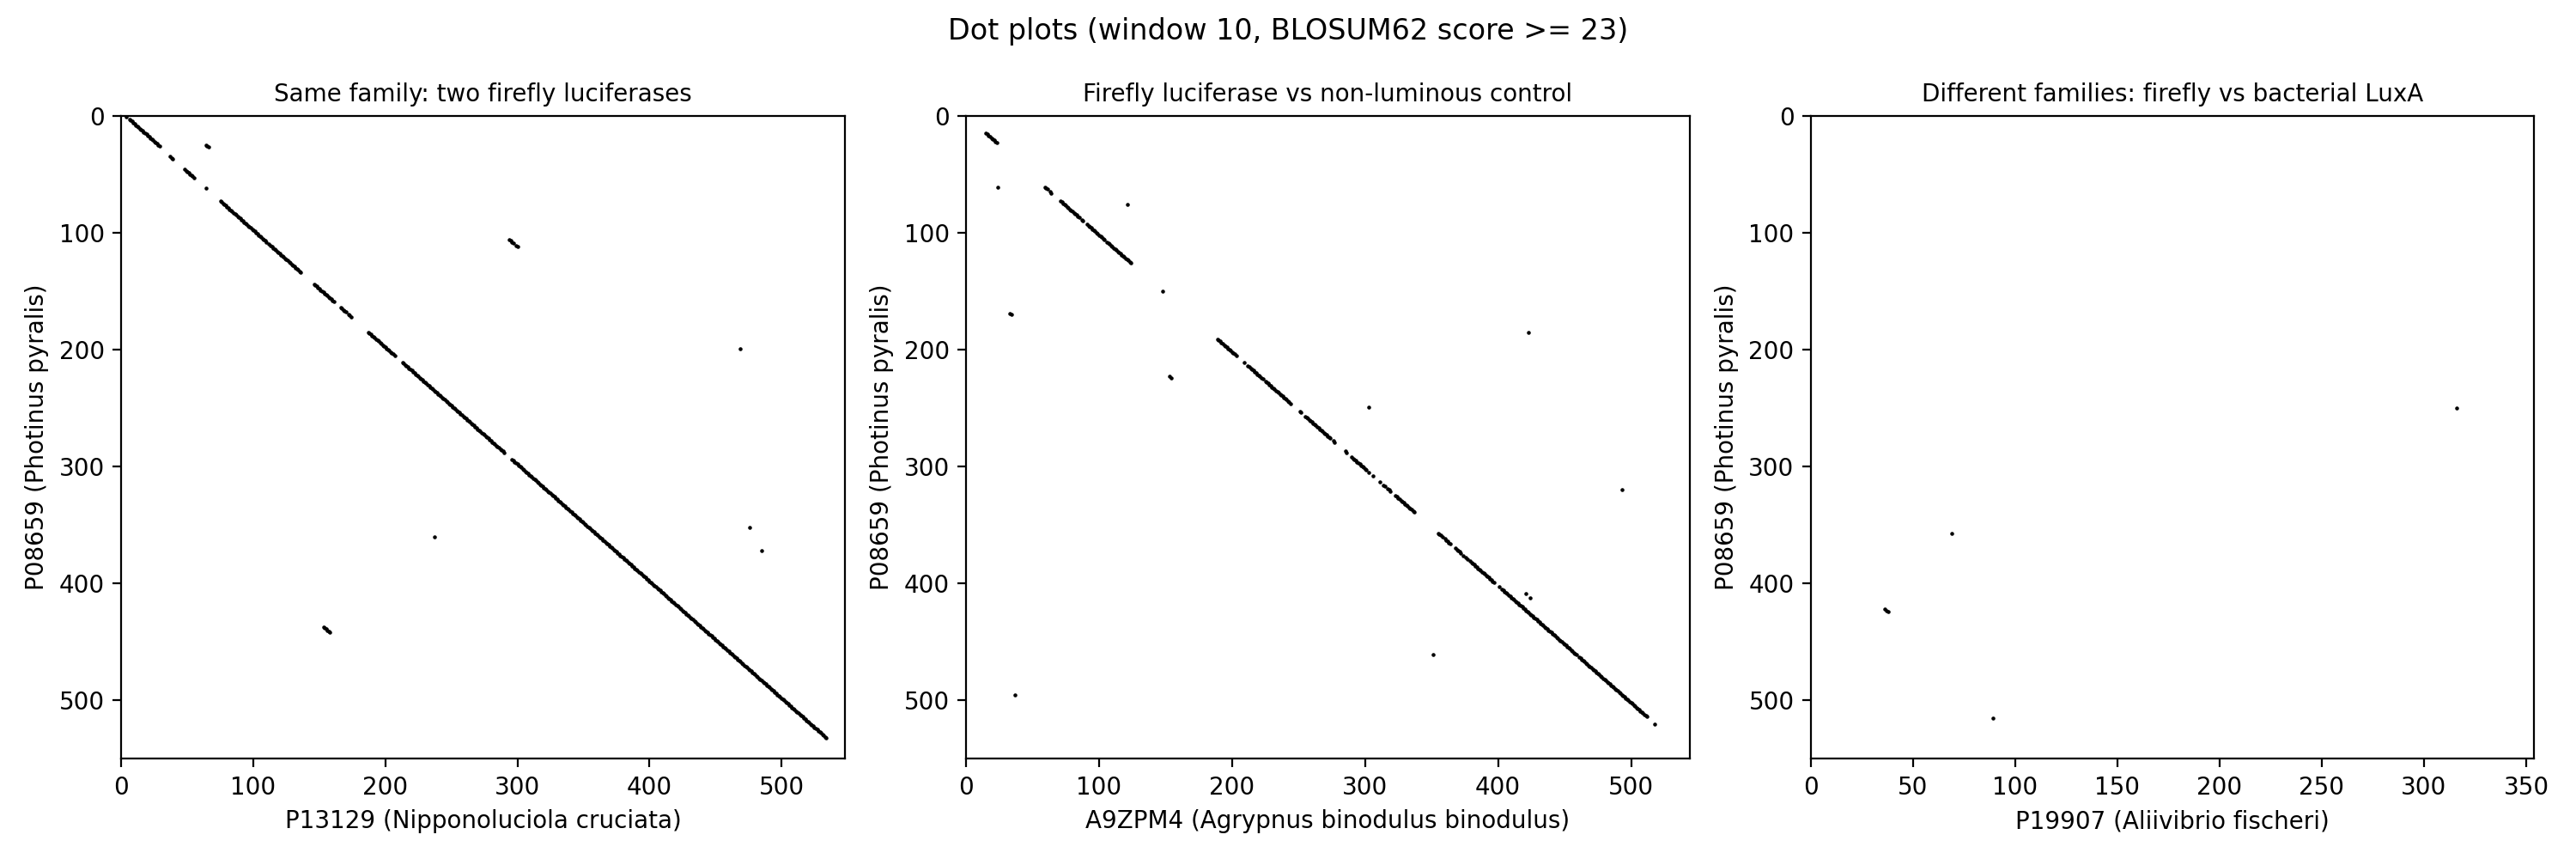

In [6]:
from src import dotplot
dotplot.run()
display(Image('results/figures/dotplots.png', width=900))

## 5. BLAST (W12)
Local BLAST+ all-vs-all at E < 0.001.

In [7]:
from src import blast
blast.run()

684 hits at E < 0.001; 15 of 81 queries hit another family
                           same_family_hits  cross_family_hits
family         role                                           
firefly        luciferase                72                 40
renilla_type   luciferase                15                  0
bacterial_luxa luciferase                95                  0
fungal_luz     luciferase                99                  0
copepod        luciferase                90                  0
dinoflagellate luciferase                56                  0
ostracod       luciferase                 6                  0
click_beetle   luciferase                16                 40
               control                    4                 10
firefly        control                   18                 10
renilla_type   control                   15                  0
bacterial_luxa control                   11                  0
fungal_luz     control                   33                

,accession,family,role,same_family_hits,cross_family_hits,cross_family_subjects,best_cross_family_evalue
0,P08659,firefly,luciferase,9,5,A0A0C6E621 A0A0C6E0Y4 Q718A7 A9ZPM4 D2KV86,0.0
1,P13129,firefly,luciferase,9,5,A0A0C6E621 A0A0C6E0Y4 Q718A7 A9ZPM4 D2KV86,0.0
2,Q26304,firefly,luciferase,9,5,A0A0C6E621 A0A0C6E0Y4 Q718A7 A9ZPM4 D2KV86,0.0
3,Q01158,firefly,luciferase,9,5,A0A0C6E621 A0A0C6E0Y4 Q718A7 D2KV86 A9ZPM4,0.0
4,Q27757,firefly,luciferase,9,5,A0A0C6E621 A9ZPM4 Q718A7 A0A0C6E0Y4 D2KV86,0.0
...,...,...,...,...,...,...,...
76,P62152,photoprotein,control,6,0,,NaN
77,Q9GV45,decapod_shrimp,luciferase,1,0,,NaN
78,P29498,decapod_shrimp,control,3,0,,NaN
79,P41509,decapod_shrimp,control,2,0,,NaN


## 6. Within-family trees (W10)
Neighbour-joining from Poisson distances. No tree mixes families: unrelated proteins cannot be meaningfully aligned together.

firefly: 10 sequences
renilla_type: 6 sequences
bacterial_luxa: 13 sequences
fungal_luz: 12 sequences
copepod: 10 sequences
dinoflagellate: 8 sequences


ostracod: 3 sequences
click_beetle: 5 sequences
photoprotein: 10 sequences
decapod_shrimp: 4 sequences


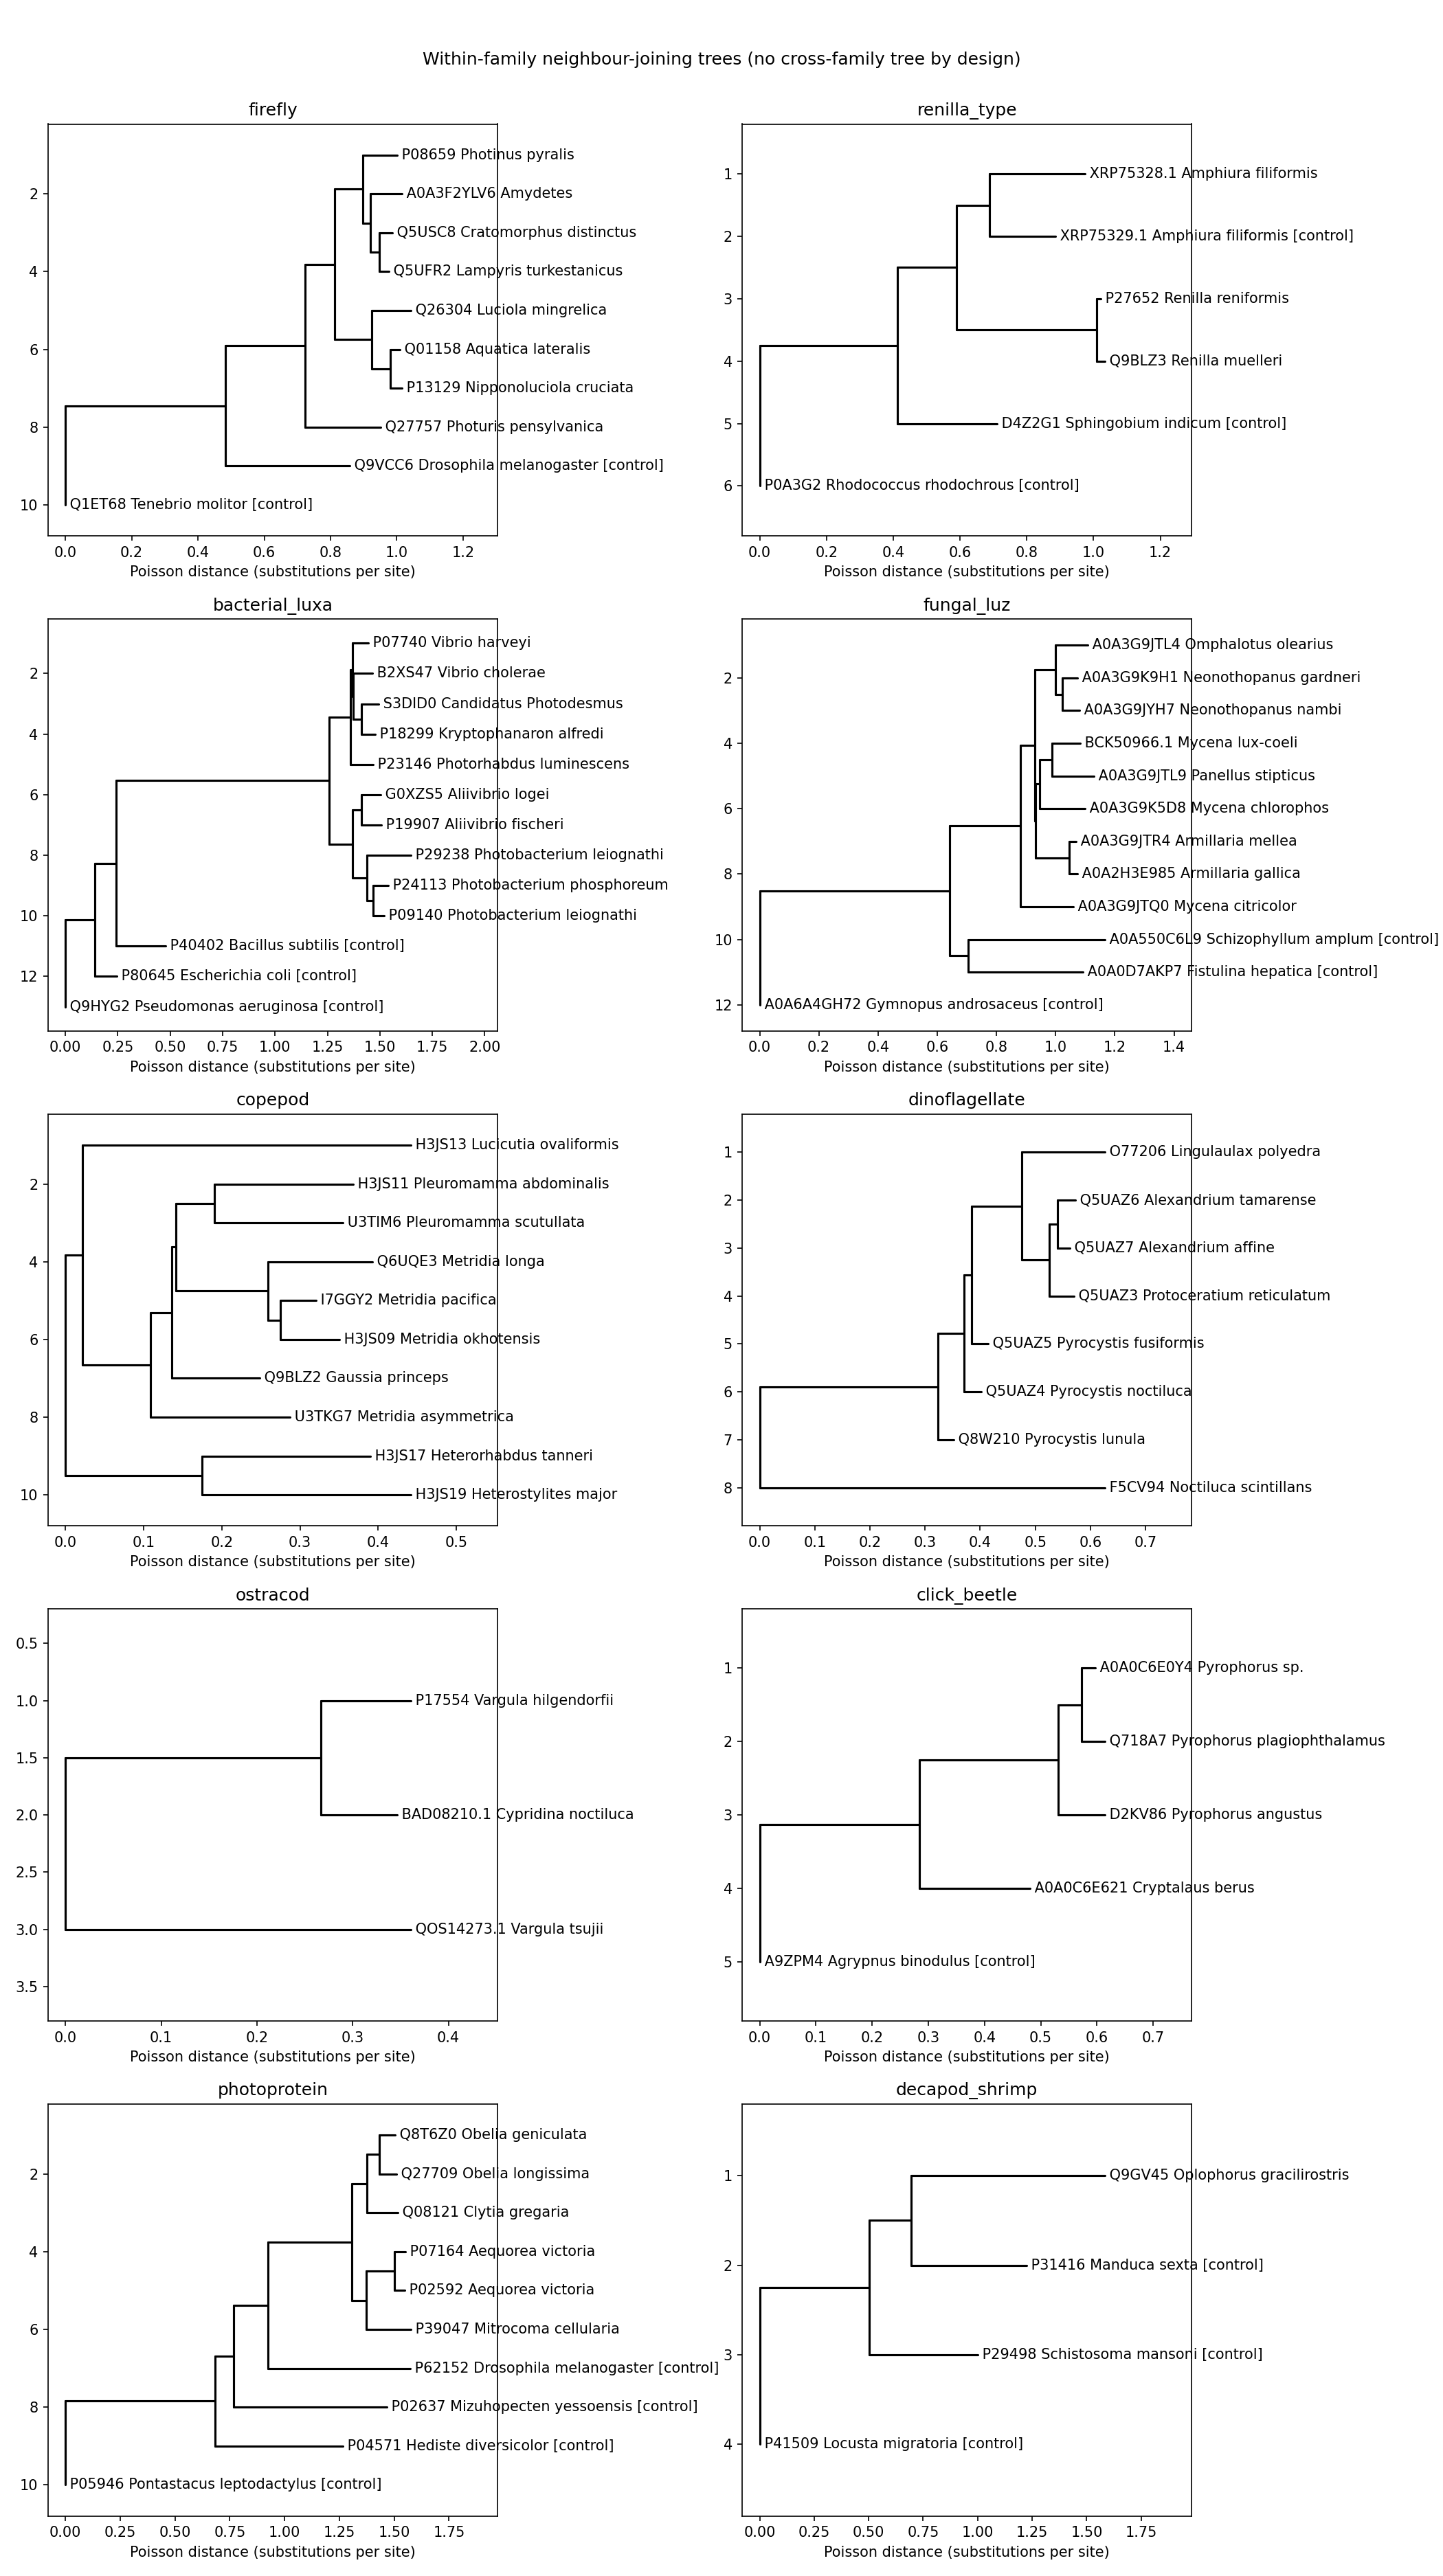

In [8]:
from src import phylo
phylo.run()
display(Image('results/figures/trees.png', width=800))

## 7. Clustering and statistics (W11)
Do luciferases group by family, or by "makes light"? Do luciferases differ from their own controls in a consistent direction?

                                             test           feature  statistic      p_value  n
  Ward clustering vs family (adjusted Rand index)   all composition   0.820922          NaN 62
     Kruskal-Wallis across 10 luciferase families             gravy  54.156767 1.762609e-08 62
     Kruskal-Wallis across 10 luciferase families isoelectric_point  47.416701 3.281951e-07 62
     Kruskal-Wallis across 10 luciferase families       aromaticity  52.771862 3.228924e-08 62
     Kruskal-Wallis across 10 luciferase families          aa_C_pct  53.332512 2.527787e-08 62
Sign test: luciferase vs own control (7 families)             gravy   1.000000 1.250000e-01  7
Sign test: luciferase vs own control (7 families) isoelectric_point   3.000000 1.000000e+00  7
Sign test: luciferase vs own control (7 families)       aromaticity   6.000000 1.250000e-01  7
Sign test: luciferase vs own control (7 families)          aa_C_pct   5.000000 4.531250e-01  7
family            bacterial_luxa click_beetle deca

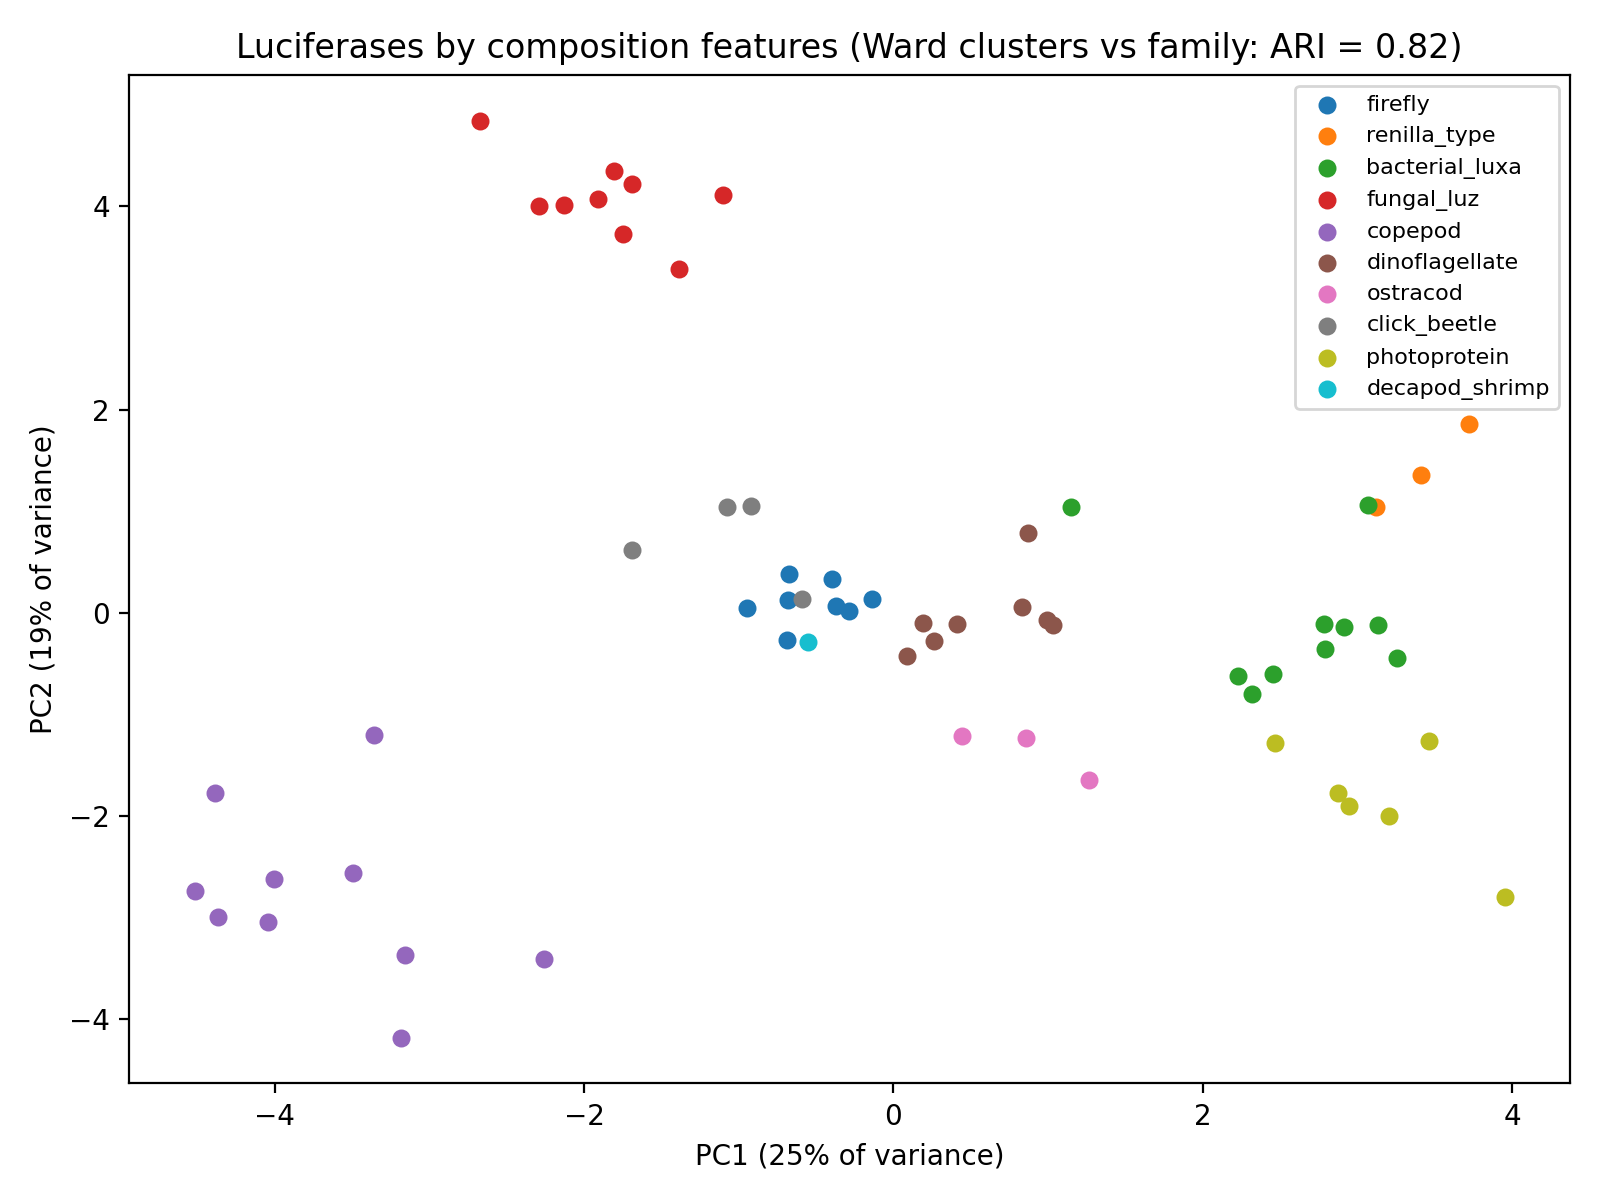

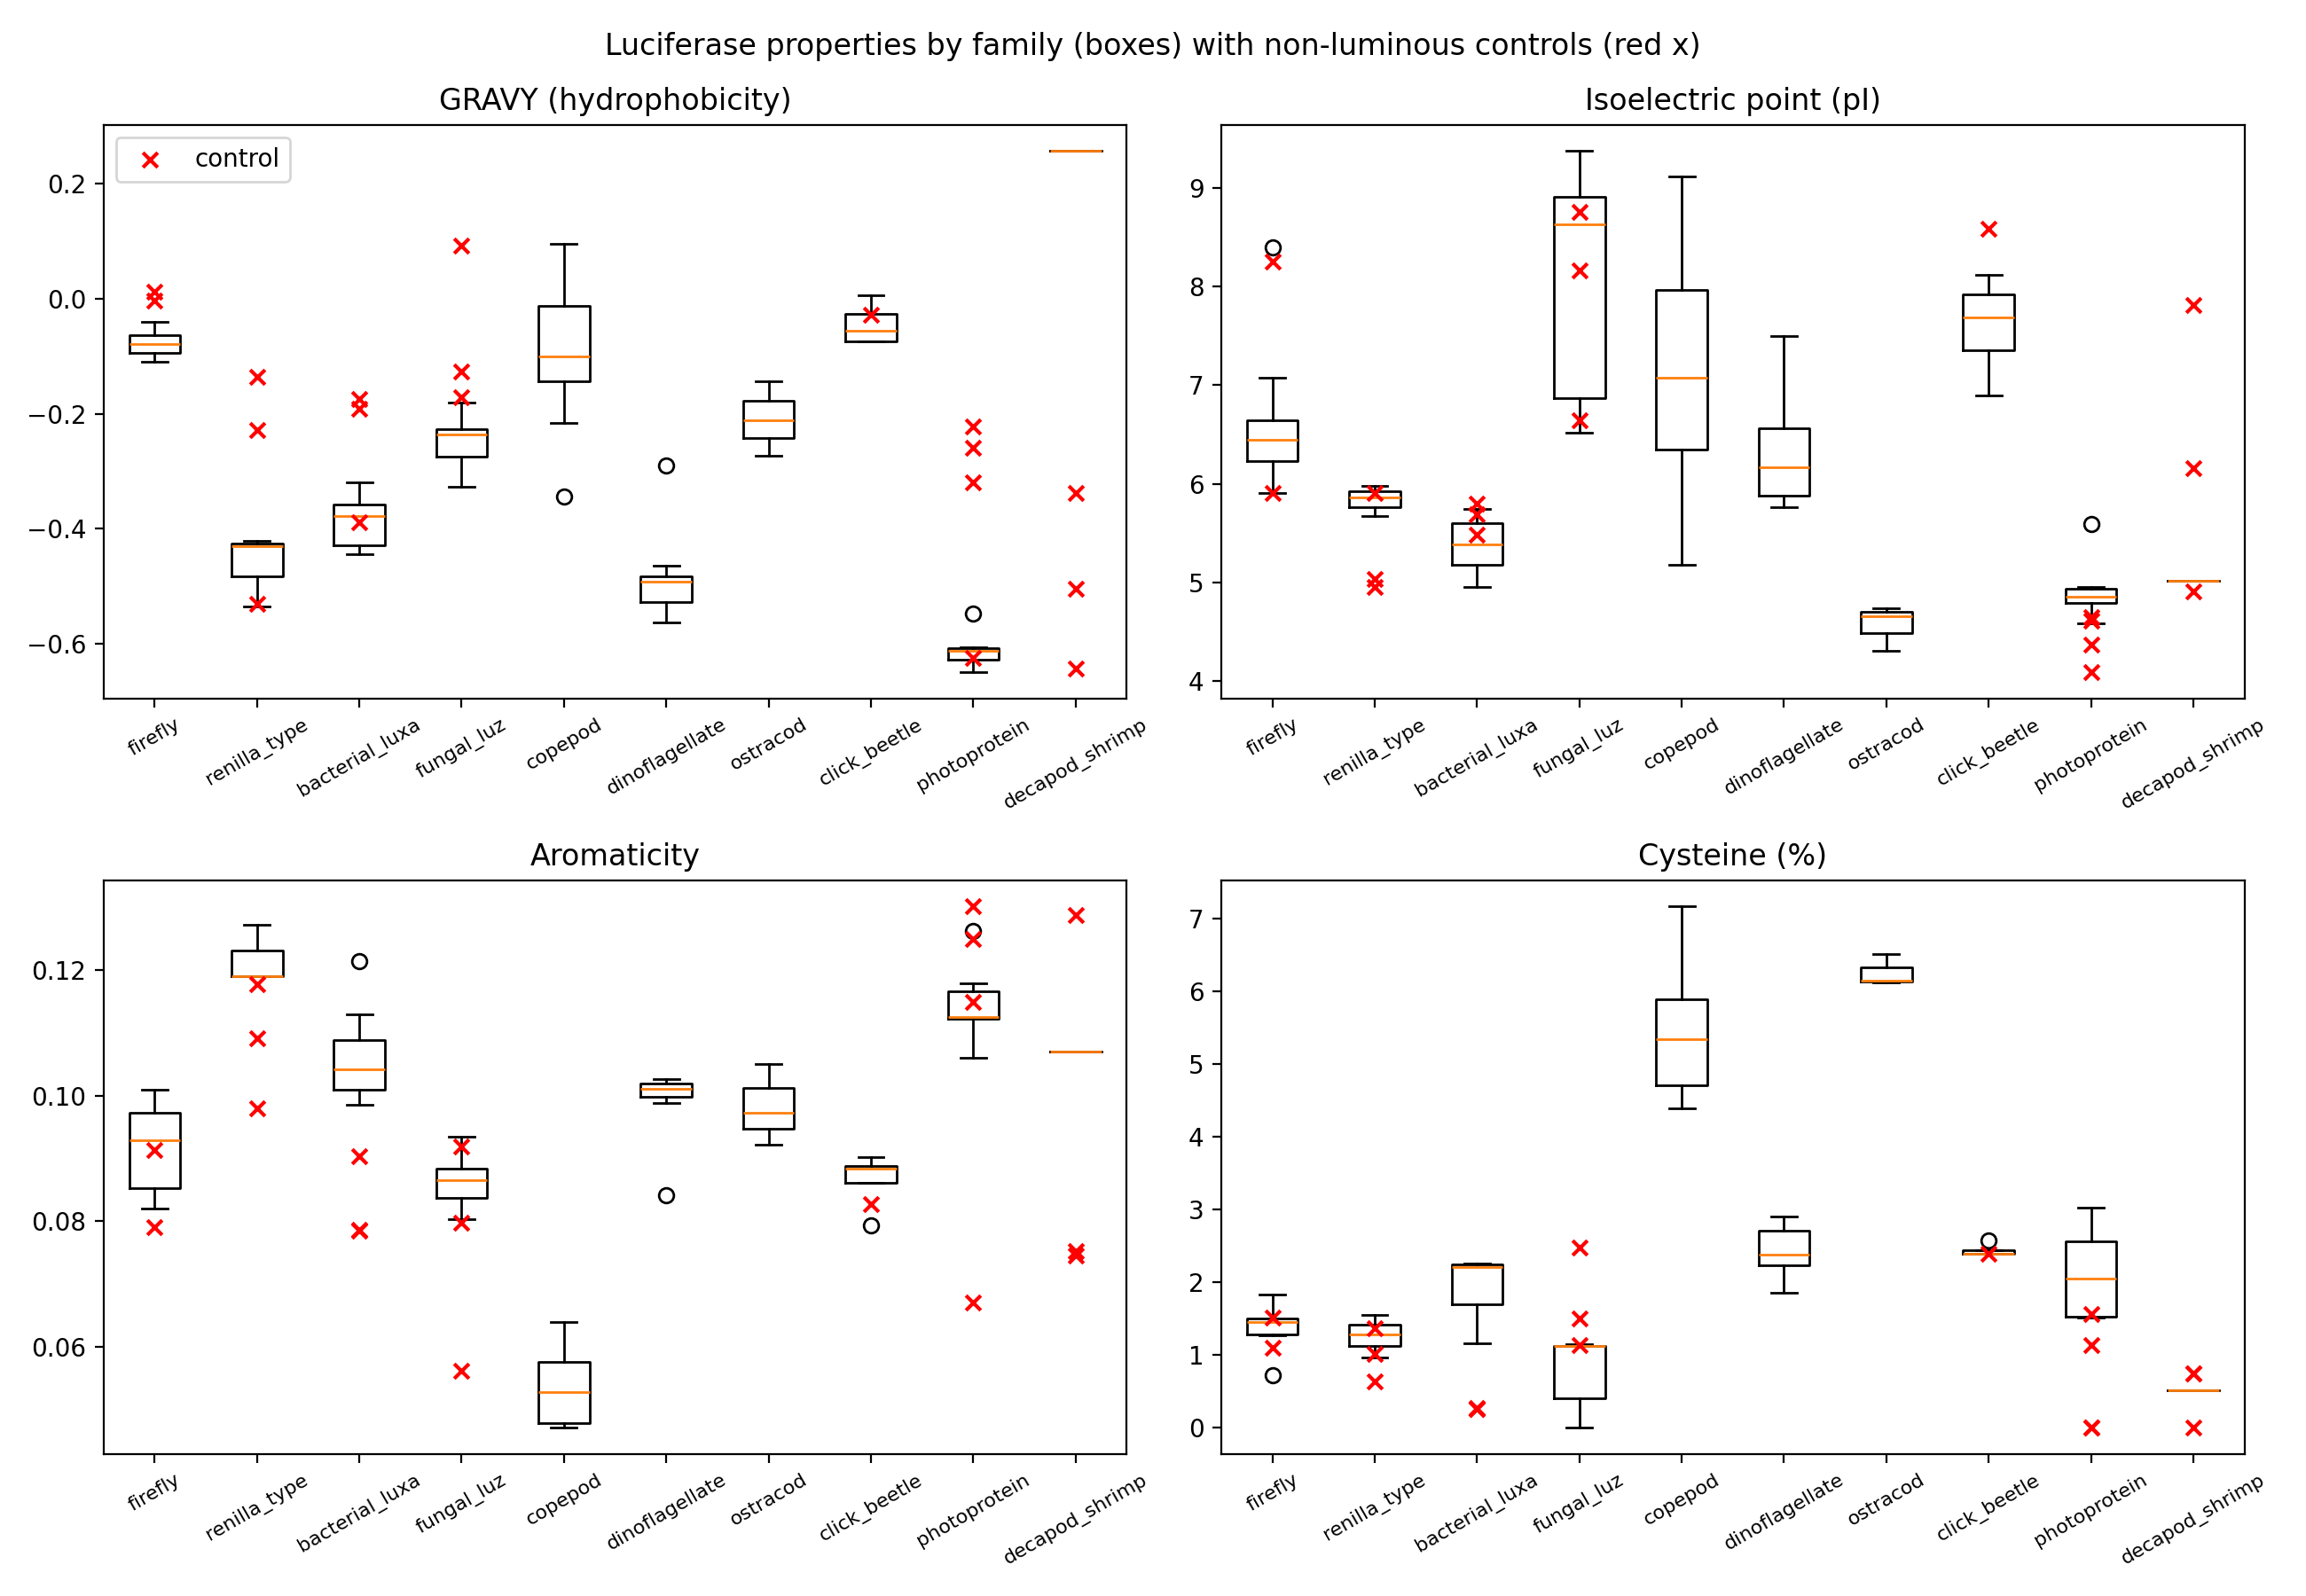

In [9]:
from src import analysis
analysis.run()
display(Image('results/figures/pca_features.png', width=650))
display(Image('results/figures/feature_boxplots.png', width=850))

In [10]:
pd.read_csv('results/control_comparison.csv')

,family,feature,luciferase_median,control_median,difference,direction
0,firefly,gravy,-0.0795,0.0039,-0.0835,lower
1,firefly,isoelectric_point,6.4495,7.0819,-0.6324,lower
2,firefly,aromaticity,0.0930,0.0852,0.0078,higher
3,firefly,aa_C_pct,1.4599,1.3119,0.1480,higher
4,renilla_type,gravy,-0.4299,-0.2280,-0.2019,lower
5,renilla_type,isoelectric_point,5.8602,5.0291,0.8311,higher
6,renilla_type,aromaticity,0.1190,0.1092,0.0098,higher
7,renilla_type,aa_C_pct,1.2862,1.0135,0.2727,higher
8,bacterial_luxa,gravy,-0.3781,-0.1916,-0.1865,lower
9,bacterial_luxa,isoelectric_point,5.3839,5.6939,-0.3100,lower


## 3b. Dynamic programming by hand (W8)
A hand-written Needleman–Wunsch table and traceback, checked against Biopython.

In [11]:
print(open('results/dp_example.txt').read())

Needleman-Wunsch DP table: HEAGAWGHEE vs PAWHEAE (BLOSUM62, linear gap -8)

      -    P    A    W    H    E    A    E
 -    0   -8  -16  -24  -32  -40  -48  -56
 H   -8   -2  -10  -18  -16  -24  -32  -40
 E  -16   -9   -3  -11  -18  -11  -19  -27
 A  -24  -17   -5   -6  -13  -19   -7  -15
 G  -32  -25  -13   -7   -8  -15  -15   -9
 A  -40  -33  -21  -15   -9   -9  -11  -16
 W  -48  -41  -29  -10  -17  -12  -12  -14
 G  -56  -49  -37  -18  -12  -19  -12  -14
 H  -64  -57  -45  -26  -10  -12  -20  -12
 E  -72  -65  -53  -34  -18   -5  -13  -15
 E  -80  -73  -61  -42  -26  -13   -6   -8

Optimal alignment (score -8):
HEAGAWGHEE
--P-AWHEAE

Biopython score for the same settings: -8 (matches the hand-written DP)



## 7b. Motif search with multiple pattern matching (W2, W12) and GO terms (W3)
Every PROSITE pattern listed for the dataset is scanned against every protein.

In [12]:
from src import motifs
motifs.run()
pd.read_csv('results/go_by_family.csv')

4 PROSITE patterns; 57 matches
prosite_id  name                
PS00018     EF_HAND_1                        photoprotein
PS00455     AMP_BINDING             click_beetle, firefly
PS00494     BACTERIAL_LUCIFERASE           bacterial_luxa


,family,role,n,go_molecular_function
0,firefly,luciferase,8,CoA-ligase activity; Photinus-luciferin 4-mono...
1,firefly,control,2,CoA-ligase activity; long-chain fatty acid-CoA...
2,renilla_type,luciferase,3,Renilla-luciferin 2-monooxygenase activity; ca...
3,renilla_type,control,3,haloalkane dehalogenase activity
4,bacterial_luxa,luciferase,10,alkanal monooxygenase (FMN-linked) activity
5,bacterial_luxa,control,3,alkanesulfonate monooxygenase activity; identi...
6,fungal_luz,luciferase,9,NaN
7,fungal_luz,control,3,NaN
8,copepod,luciferase,10,Renilla-luciferin 2-monooxygenase activity; lu...
9,dinoflagellate,luciferase,8,luciferin monooxygenase activity; oxidoreducta...


## 7c. In-silico trypsin digest (W5, W14)

In [13]:
from src import digest
digest.run()

1976 tryptic peptides (6-30 aa); 2 distinct peptides occur in more than one family
peptide
EVGEAVAK    click_beetle, firefly
GVMLTHK     click_beetle, firefly


,family,role,proteins,peptides,shared_with_other_family
0,firefly,luciferase,8,234,5
1,firefly,control,2,62,0
2,renilla_type,luciferase,3,70,0
3,renilla_type,control,3,56,0
4,bacterial_luxa,luciferase,10,157,0
5,bacterial_luxa,control,3,58,0
6,fungal_luz,luciferase,9,144,0
7,fungal_luz,control,3,50,0
8,copepod,luciferase,10,123,0
9,dinoflagellate,luciferase,8,632,0


## 7d. AlphaFold structure confidence (W15)

In [14]:
from src import structure
structure.run();

AlphaFold models for 76 of 81 proteins
                           count  median   min
family         role                           
firefly        luciferase      8    92.9  92.1
               control         2    91.2  91.0
renilla_type   luciferase      2    96.8  96.7
               control         2    98.2  98.1
bacterial_luxa luciferase     10    90.9  87.9
               control         3    95.3  94.8
fungal_luz     luciferase      8    90.7  88.1
               control         3    89.1  87.8
copepod        luciferase     10    55.7  49.2
dinoflagellate luciferase      8    86.0  79.1
ostracod       luciferase      1    73.4  73.4
click_beetle   luciferase      4    89.5  89.0
               control         1    89.2  89.2
photoprotein   luciferase      6    91.7  89.1
               control         4    93.7  85.8
decapod_shrimp luciferase      1    84.7  84.7
               control         3    91.2  90.8


## 7e. Novelty: pre-registered, family-aware convergence test
The prediction (lower GRAVY, higher aromaticity than own controls) was committed in `d2978e2` before the photoprotein and Oplophorus families were added. Labels are permuted only within families.

In [15]:
from src import convergence
tests = convergence.run()

        family     feature  difference predicted_direction observed_direction
  photoprotein       gravy    -0.32175               lower              lower
decapod_shrimp       gravy     0.76040               lower             higher
  photoprotein aromaticity    -0.00745              higher              lower
decapod_shrimp aromaticity     0.03190              higher             higher

Pre-registered replication: FAILED

                                                        analysis           feature  families  families_in_predicted_direction  sign_test_p_one_sided  permutation_p_one_sided  permutation_p_holm  permutation_p_two_sided
                 Replication: new families only (pre-registered)             gravy         2                              1.0               0.750000                 0.758324            0.758324                      NaN
                 Replication: new families only (pre-registered)       aromaticity         2                              1.0          

## 7f. Novelty: surface vs core in AlphaFold models (exploratory)

In [16]:
from src import pockets
pockets.run();

AlphaFold models analysed: 76
                      family      set        proteins  aromatic_pct_buried  aromatic_pct_exposed  hydropathy_buried  hydropathy_exposed
                     firefly original  8 luc / 2 ctrl             0.035988              1.978576          -0.265921            0.078868
                renilla_type original  2 luc / 2 ctrl             3.741864             -0.763304           0.084469           -0.598278
              bacterial_luxa original 10 luc / 3 ctrl             0.171362              3.451501           0.066938           -0.252131
                  fungal_luz original  8 luc / 3 ctrl            -0.361094              1.008272          -0.240706           -0.269981
                click_beetle original  4 luc / 1 ctrl             0.267977              1.649595          -0.063154            0.136181
                photoprotein      new  6 luc / 4 ctrl            -5.083018              4.446040          -0.256210           -0.373684
              deca

## 8. Conclusion

- Independent luminous families (11 origins) share **no** detectable sequence, motifs or peptides; only firefly and click beetle (one ancestral enzyme family) overlap.
- Composition sorts proteins by family (ARI ≈ 0.82): ancestry dominates.
- **Novelty:** a pre-registered replication **failed** for GRAVY. Aromaticity is higher in luminous proteins than in their own non-luminous relatives across 7 families (family-stratified permutation p ≈ 0.010), and the excess sits on **exposed** residues (exploratory, p ≈ 0.0001). Sharing coelenterazine does not make proteins alike (p ≈ 0.995).
- **Answer:** convergence in function, not sequence, with one cautious, surface-located aromatic association. Full write-up: `docs/FINAL_REPORT.md` / `.pdf`.